In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
data_path = (
    "/content/drive/MyDrive/"
    "AutoSenseAI/data/duration/"
    "service_duration_benchmark.csv"
)

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (314, 11)


,fix_id,code_id,fix_title,probability_rank,difficulty_level,est_parts_cost_min_usd,est_parts_cost_max_usd,parts_cost_mid_usd,parts_cost_range_usd,est_labor_hours,labor_minutes
0,849,213,Inspect wheel speed sensor connector and harne...,1,Easy DIY,5.0,25.0,15.0,20.0,0.4,24.0
1,850,213,Test wheel speed sensor resistance and signal,2,Moderate DIY,10.0,40.0,25.0,30.0,0.6,36.0
2,851,213,Replace wheel speed sensor,3,Moderate DIY,30.0,120.0,75.0,90.0,0.6,36.0
3,852,213,Repair chafed wheel speed sensor harness wiring,4,Professional Required,15.0,65.0,40.0,50.0,1.2,72.0
4,865,217,Inspect wheel speed sensor connector and harne...,1,Easy DIY,5.0,25.0,15.0,20.0,0.4,24.0


In [4]:
print(df.columns.tolist())

print("\nRows:", len(df))
print("Unique repair titles:", df["fix_title"].nunique())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget summary:")
print(df["est_labor_hours"].describe())

['fix_id', 'code_id', 'fix_title', 'probability_rank', 'difficulty_level', 'est_parts_cost_min_usd', 'est_parts_cost_max_usd', 'parts_cost_mid_usd', 'parts_cost_range_usd', 'est_labor_hours', 'labor_minutes']

Rows: 314
Unique repair titles: 174

Missing values:
fix_id                    0
code_id                   0
fix_title                 0
probability_rank          0
difficulty_level          0
est_parts_cost_min_usd    0
est_parts_cost_max_usd    0
parts_cost_mid_usd        0
parts_cost_range_usd      0
est_labor_hours           0
labor_minutes             0
dtype: int64

Target summary:
count    314.000000
mean       1.069745
std        0.761373
min        0.200000
25%        0.600000
50%        1.000000
75%        1.300000
max        4.500000
Name: est_labor_hours, dtype: float64


In [5]:
target = "est_labor_hours"

y = df[target].copy()
groups = df["fix_title"].copy()

print("Target:", target)
print("Total records:", len(y))
print("Unique groups:", groups.nunique())

Target: est_labor_hours
Total records: 314
Unique groups: 174


In [6]:
task_only_features = [
    "fix_title",
    "difficulty_level",
    "probability_rank"
]

In [7]:
task_cost_features = [
    "fix_title",
    "difficulty_level",
    "probability_rank",
    "parts_cost_mid_usd",
    "parts_cost_range_usd"
]

print("Task-only:", task_only_features)
print("Task + Cost:", task_cost_features)

Task-only: ['fix_title', 'difficulty_level', 'probability_rank']
Task + Cost: ['fix_title', 'difficulty_level', 'probability_rank', 'parts_cost_mid_usd', 'parts_cost_range_usd']


In [8]:
def create_task_only_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "title_text",
                TfidfVectorizer(
                    lowercase=True,
                    ngram_range=(1, 2),
                    min_df=1,
                    max_features=1000
                ),
                "fix_title"
            ),

            (
                "difficulty",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                ["difficulty_level"]
            ),

            (
                "numeric",
                SimpleImputer(
                    strategy="median"
                ),
                ["probability_rank"]
            )
        ]
    )

In [9]:
def create_task_cost_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "title_text",
                TfidfVectorizer(
                    lowercase=True,
                    ngram_range=(1, 2),
                    min_df=1,
                    max_features=1000
                ),
                "fix_title"
            ),

            (
                "difficulty",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                ["difficulty_level"]
            ),

            (
                "numeric",
                SimpleImputer(
                    strategy="median"
                ),
                [
                    "probability_rank",
                    "parts_cost_mid_usd",
                    "parts_cost_range_usd"
                ]
            )
        ]
    )

In [10]:
rf_task_pipeline = Pipeline([
    (
        "preprocessor",
        create_task_only_preprocessor()
    ),
    (
        "regressor",
        RandomForestRegressor(
            n_estimators=500,
            max_depth=12,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
])

print("RF Task Only pipeline ready.")

RF Task Only pipeline ready.


In [11]:
rf_cost_pipeline = Pipeline([
    (
        "preprocessor",
        create_task_cost_preprocessor()
    ),
    (
        "regressor",
        RandomForestRegressor(
            n_estimators=500,
            max_depth=12,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
    )
])

print("RF Task + Cost pipeline ready.")

RF Task + Cost pipeline ready.


In [12]:
xgb_task_pipeline = Pipeline([
    (
        "preprocessor",
        create_task_only_preprocessor()
    ),
    (
        "regressor",
        XGBRegressor(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=2,
            reg_lambda=1.0,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )
    )
])

print("XGB Task Only pipeline ready.")

XGB Task Only pipeline ready.


In [13]:
xgb_cost_pipeline = Pipeline([
    (
        "preprocessor",
        create_task_cost_preprocessor()
    ),
    (
        "regressor",
        XGBRegressor(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=2,
            reg_lambda=1.0,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        )
    )
])

print("XGB Task + Cost pipeline ready.")

XGB Task + Cost pipeline ready.


In [14]:
group_cv = GroupKFold(
    n_splits=5
)

print(group_cv)

GroupKFold(n_splits=5, random_state=None, shuffle=False)


In [15]:
scoring = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "r2": "r2"
}

In [16]:
def evaluate_group_cv(
    model_name,
    pipeline,
    features,
    df,
    y,
    groups
):
    X = df[features]

    results = cross_validate(
        pipeline,
        X,
        y,
        groups=groups,
        cv=group_cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False
    )

    mae = -results["test_mae"]
    rmse = np.sqrt(
        -results["test_mse"]
    )
    r2 = results["test_r2"]

    summary = {
        "Model": model_name,

        "Mean_MAE_Hours": mae.mean(),
        "Mean_MAE_Minutes": mae.mean() * 60,

        "MAE_Std_Minutes": mae.std() * 60,

        "Mean_RMSE_Hours": rmse.mean(),
        "Mean_RMSE_Minutes": rmse.mean() * 60,

        "Mean_R2": r2.mean(),
        "R2_Std": r2.std()
    }

    fold_results = pd.DataFrame({
        "Fold": range(1, 6),
        "MAE_Hours": mae,
        "MAE_Minutes": mae * 60,
        "RMSE_Hours": rmse,
        "RMSE_Minutes": rmse * 60,
        "R2": r2
    })

    return summary, fold_results

In [17]:
rf_task_summary, rf_task_folds = evaluate_group_cv(
    "Random Forest - Task Only",
    rf_task_pipeline,
    task_only_features,
    df,
    y,
    groups
)

rf_task_summary

{'Model': 'Random Forest - Task Only',
 'Mean_MAE_Hours': np.float64(0.28737802345488495),
 'Mean_MAE_Minutes': np.float64(17.242681407293098),
 'MAE_Std_Minutes': np.float64(5.142358376817104),
 'Mean_RMSE_Hours': np.float64(0.47774263588134325),
 'Mean_RMSE_Minutes': np.float64(28.664558152880595),
 'Mean_R2': np.float64(0.5539299559648152),
 'R2_Std': np.float64(0.11234888796731571)}

In [18]:
rf_cost_summary, rf_cost_folds = evaluate_group_cv(
    "Random Forest - Task + Cost",
    rf_cost_pipeline,
    task_cost_features,
    df,
    y,
    groups
)

rf_cost_summary

{'Model': 'Random Forest - Task + Cost',
 'Mean_MAE_Hours': np.float64(0.23293856268914817),
 'Mean_MAE_Minutes': np.float64(13.97631376134889),
 'MAE_Std_Minutes': np.float64(3.9916980938986804),
 'Mean_RMSE_Hours': np.float64(0.39494085819656594),
 'Mean_RMSE_Minutes': np.float64(23.696451491793955),
 'Mean_R2': np.float64(0.6421036659842106),
 'R2_Std': np.float64(0.19408874943221702)}

In [19]:
xgb_task_summary, xgb_task_folds = evaluate_group_cv(
    "XGBoost - Task Only",
    xgb_task_pipeline,
    task_only_features,
    df,
    y,
    groups
)

xgb_task_summary

{'Model': 'XGBoost - Task Only',
 'Mean_MAE_Hours': np.float64(0.33549387311422696),
 'Mean_MAE_Minutes': np.float64(20.12963238685362),
 'MAE_Std_Minutes': np.float64(5.604932248315158),
 'Mean_RMSE_Hours': np.float64(0.5690659019601514),
 'Mean_RMSE_Minutes': np.float64(34.143954117609084),
 'Mean_R2': np.float64(0.3409011892473055),
 'R2_Std': np.float64(0.06351119307750065)}

In [20]:
xgb_cost_summary, xgb_cost_folds = evaluate_group_cv(
    "XGBoost - Task + Cost",
    xgb_cost_pipeline,
    task_cost_features,
    df,
    y,
    groups
)

xgb_cost_summary

{'Model': 'XGBoost - Task + Cost',
 'Mean_MAE_Hours': np.float64(0.25532919061135095),
 'Mean_MAE_Minutes': np.float64(15.319751436681058),
 'MAE_Std_Minutes': np.float64(2.6984058492324854),
 'Mean_RMSE_Hours': np.float64(0.41113512811491065),
 'Mean_RMSE_Minutes': np.float64(24.66810768689464),
 'Mean_R2': np.float64(0.6048642226257147),
 'R2_Std': np.float64(0.16963615358554418)}

In [21]:
final_comparison = pd.DataFrame([
    rf_task_summary,
    rf_cost_summary,
    xgb_task_summary,
    xgb_cost_summary
])

final_comparison

,Model,Mean_MAE_Hours,Mean_MAE_Minutes,MAE_Std_Minutes,Mean_RMSE_Hours,Mean_RMSE_Minutes,Mean_R2,R2_Std
0,Random Forest - Task Only,0.287378,17.242681,5.142358,0.477743,28.664558,0.553930,0.112349
1,Random Forest - Task + Cost,0.232939,13.976314,3.991698,0.394941,23.696451,0.642104,0.194089
2,XGBoost - Task Only,0.335494,20.129632,5.604932,0.569066,34.143954,0.340901,0.063511
3,XGBoost - Task + Cost,0.255329,15.319751,2.698406,0.411135,24.668108,0.604864,0.169636


In [22]:
final_sorted = final_comparison.sort_values(
    by="Mean_MAE_Minutes",
    ascending=True
)

final_sorted

,Model,Mean_MAE_Hours,Mean_MAE_Minutes,MAE_Std_Minutes,Mean_RMSE_Hours,Mean_RMSE_Minutes,Mean_R2,R2_Std
1,Random Forest - Task + Cost,0.232939,13.976314,3.991698,0.394941,23.696451,0.642104,0.194089
3,XGBoost - Task + Cost,0.255329,15.319751,2.698406,0.411135,24.668108,0.604864,0.169636
0,Random Forest - Task Only,0.287378,17.242681,5.142358,0.477743,28.664558,0.553930,0.112349
2,XGBoost - Task Only,0.335494,20.129632,5.604932,0.569066,34.143954,0.340901,0.063511


In [23]:
display_columns = [
    "Model",
    "Mean_MAE_Minutes",
    "MAE_Std_Minutes",
    "Mean_RMSE_Minutes",
    "Mean_R2"
]

final_sorted[
    display_columns
].round(3)

,Model,Mean_MAE_Minutes,MAE_Std_Minutes,Mean_RMSE_Minutes,Mean_R2
1,Random Forest - Task + Cost,13.976,3.992,23.696,0.642
3,XGBoost - Task + Cost,15.320,2.698,24.668,0.605
0,Random Forest - Task Only,17.243,5.142,28.665,0.554
2,XGBoost - Task Only,20.130,5.605,34.144,0.341


In [24]:
rf_task_mae = rf_task_summary[
    "Mean_MAE_Minutes"
]

rf_cost_mae = rf_cost_summary[
    "Mean_MAE_Minutes"
]

rf_cost_improvement = (
    (rf_task_mae - rf_cost_mae)
    / rf_task_mae
    * 100
)

print(
    "Random Forest Task-only MAE:",
    round(rf_task_mae, 2),
    "minutes"
)

print(
    "Random Forest Task + Cost MAE:",
    round(rf_cost_mae, 2),
    "minutes"
)

print(
    "RF improvement from cost features:",
    round(rf_cost_improvement, 2),
    "%"
)

Random Forest Task-only MAE: 17.24 minutes
Random Forest Task + Cost MAE: 13.98 minutes
RF improvement from cost features: 18.94 %


In [25]:
xgb_task_mae = xgb_task_summary[
    "Mean_MAE_Minutes"
]

xgb_cost_mae = xgb_cost_summary[
    "Mean_MAE_Minutes"
]

xgb_cost_improvement = (
    (xgb_task_mae - xgb_cost_mae)
    / xgb_task_mae
    * 100
)

print(
    "XGBoost Task-only MAE:",
    round(xgb_task_mae, 2),
    "minutes"
)

print(
    "XGBoost Task + Cost MAE:",
    round(xgb_cost_mae, 2),
    "minutes"
)

print(
    "XGB improvement from cost features:",
    round(xgb_cost_improvement, 2),
    "%"
)

XGBoost Task-only MAE: 20.13 minutes
XGBoost Task + Cost MAE: 15.32 minutes
XGB improvement from cost features: 23.89 %


In [26]:
fold_comparison = pd.DataFrame({
    "Fold": range(1, 6),

    "RF_Task_Only": (
        rf_task_folds["MAE_Minutes"]
    ),

    "RF_Task_Cost": (
        rf_cost_folds["MAE_Minutes"]
    ),

    "XGB_Task_Only": (
        xgb_task_folds["MAE_Minutes"]
    ),

    "XGB_Task_Cost": (
        xgb_cost_folds["MAE_Minutes"]
    )
})

fold_comparison.round(2)

,Fold,RF_Task_Only,RF_Task_Cost,XGB_Task_Only,XGB_Task_Cost
0,1,16.99,12.51,21.23,15.38
1,2,11.89,10.29,17.26,15.71
2,3,19.00,12.44,21.92,12.41
3,4,25.98,21.75,28.61,20.07
4,5,12.35,12.88,11.62,13.03


In [27]:
stability_df = pd.DataFrame({
    "Model": [
        "RF Task Only",
        "RF Task + Cost",
        "XGB Task Only",
        "XGB Task + Cost"
    ],

    "MAE_Std_Minutes": [
        rf_task_folds["MAE_Minutes"].std(),
        rf_cost_folds["MAE_Minutes"].std(),
        xgb_task_folds["MAE_Minutes"].std(),
        xgb_cost_folds["MAE_Minutes"].std()
    ]
})

stability_df.sort_values(
    "MAE_Std_Minutes"
)

,Model,MAE_Std_Minutes
3,XGB Task + Cost,3.016909
1,RF Task + Cost,4.462854
0,RF Task Only,5.749331
2,XGB Task Only,6.266505


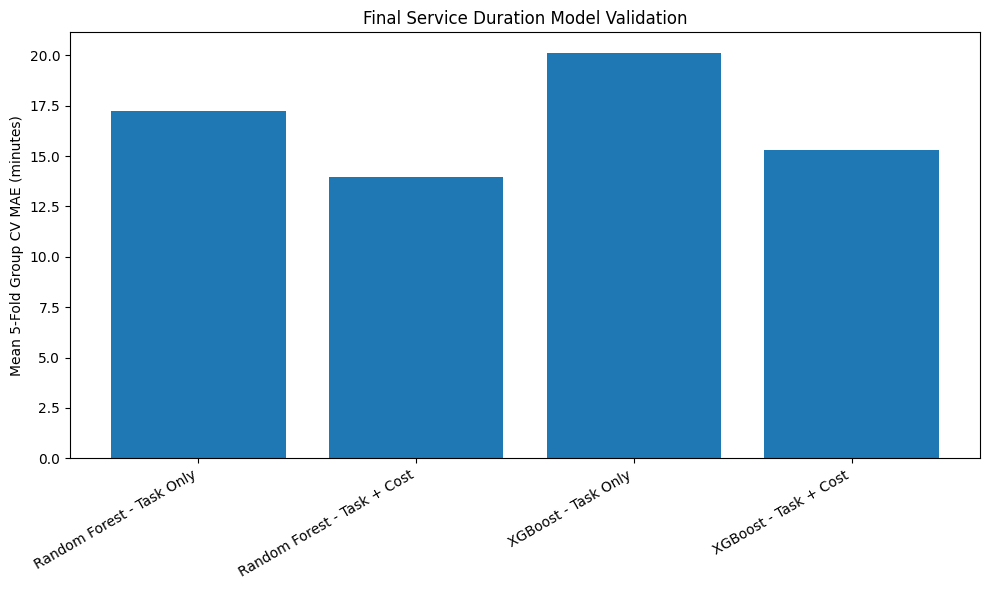

In [28]:
plt.figure(figsize=(10, 6))

plt.bar(
    final_comparison["Model"],
    final_comparison["Mean_MAE_Minutes"]
)

plt.ylabel("Mean 5-Fold Group CV MAE (minutes)")

plt.title(
    "Final Service Duration Model Validation"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()

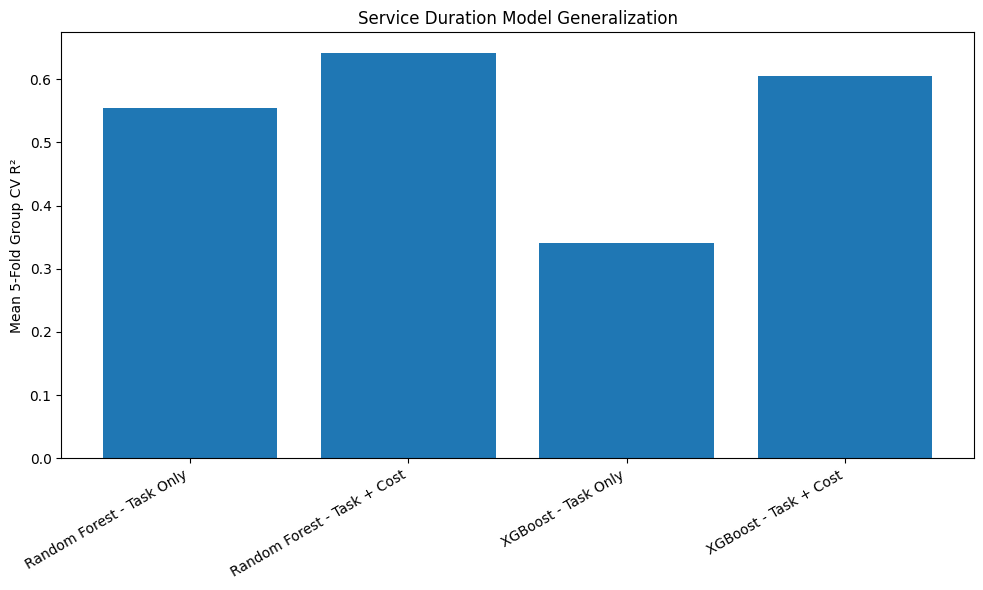

In [29]:
plt.figure(figsize=(10, 6))

plt.bar(
    final_comparison["Model"],
    final_comparison["Mean_R2"]
)

plt.ylabel("Mean 5-Fold Group CV R²")

plt.title(
    "Service Duration Model Generalization"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()

In [30]:
best_statistical_model = final_sorted.iloc[0]

print("Best statistical model:")
print(
    best_statistical_model[
        [
            "Model",
            "Mean_MAE_Minutes",
            "Mean_RMSE_Minutes",
            "Mean_R2",
            "MAE_Std_Minutes"
        ]
    ]
)

Best statistical model:
Model                Random Forest - Task + Cost
Mean_MAE_Minutes                       13.976314
Mean_RMSE_Minutes                      23.696451
Mean_R2                                 0.642104
MAE_Std_Minutes                         3.991698
Name: 1, dtype: object


In [31]:
print("Cost-feature contribution:")

print(
    "RF improvement:",
    round(rf_cost_improvement, 2),
    "%"
)

print(
    "XGB improvement:",
    round(xgb_cost_improvement, 2),
    "%"
)

print("\nInterpretation guide:")

print(
    "- >10% MAE improvement: cost features provide meaningful value."
)

print(
    "- 5-10% improvement: useful but deployment availability should be considered."
)

print(
    "- <5% improvement: Task-only model may be preferable for simplicity."
)

Cost-feature contribution:
RF improvement: 18.94 %
XGB improvement: 23.89 %

Interpretation guide:
- >10% MAE improvement: cost features provide meaningful value.
- 5-10% improvement: useful but deployment availability should be considered.
- <5% improvement: Task-only model may be preferable for simplicity.


In [32]:
results_dir = (
    "/content/drive/MyDrive/"
    "AutoSenseAI/results"
)

os.makedirs(
    results_dir,
    exist_ok=True
)

In [33]:
final_comparison.to_csv(
    os.path.join(
        results_dir,
        "duration_final_validation.csv"
    ),
    index=False
)

fold_comparison.to_csv(
    os.path.join(
        results_dir,
        "duration_fold_comparison.csv"
    ),
    index=False
)

stability_df.to_csv(
    os.path.join(
        results_dir,
        "duration_model_stability.csv"
    ),
    index=False
)

print("Validation tables saved.")

Validation tables saved.


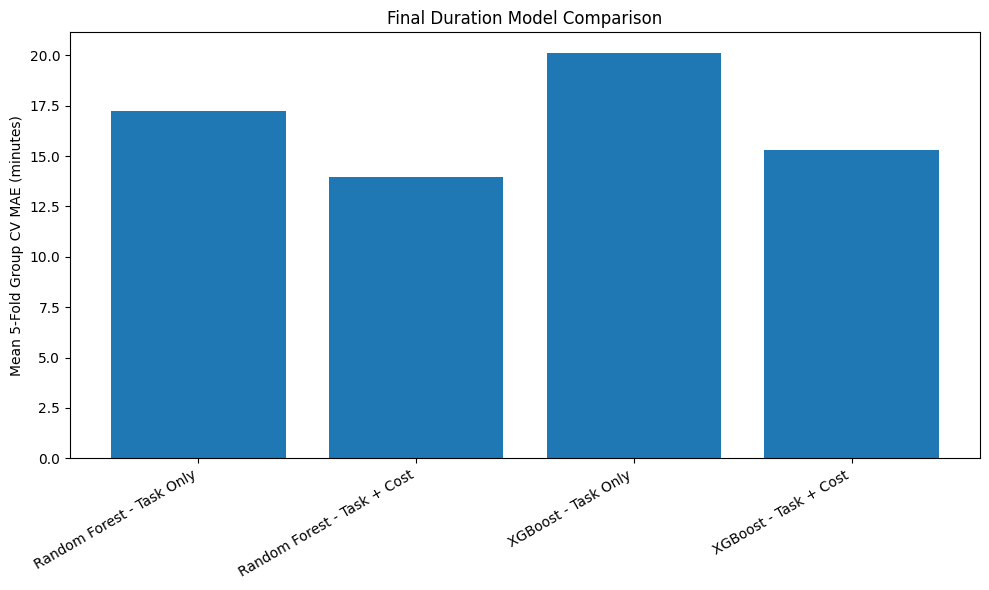

Saved: /content/drive/MyDrive/AutoSenseAI/results/duration_final_mae_comparison.png


In [34]:
plt.figure(figsize=(10, 6))

plt.bar(
    final_comparison["Model"],
    final_comparison["Mean_MAE_Minutes"]
)

plt.ylabel(
    "Mean 5-Fold Group CV MAE (minutes)"
)

plt.title(
    "Final Duration Model Comparison"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()

chart_path = os.path.join(
    results_dir,
    "duration_final_mae_comparison.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", chart_path)

## Final Duration Model Validation

Objective:
Select the most reliable regression model for service-duration estimation.

Validation Strategy:
All four candidate models were evaluated using identical 5-fold GroupKFold
cross-validation.

Grouping Variable:
fix_title

This prevents the same repair task title from appearing in both training and
validation folds and reduces repair-title memorization.

Models Compared:
1. Random Forest - Task Only
2. Random Forest - Task + Cost
3. XGBoost - Task Only
4. XGBoost - Task + Cost

Metrics:
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R²
- MAE standard deviation across folds

Practical Evaluation:
Task-only models require repair task, difficulty, and probability rank.

Task + Cost models additionally require estimated parts-cost information.

The final model should therefore be selected based not only on the lowest
prediction error, but also on stability and whether required features are
available at prediction time.

Dataset Limitation:
The target represents estimated labor hours rather than observed workshop
completion time. Therefore the selected model is treated as a benchmark
duration estimator and proof of concept until validated with real workshop
service records.

Final Selected Model:
[Complete after reviewing the validation results.]